# YOLOv10-S: análisis en test

Mismo análisis que [`04_faster_rcnn_test_analysis.ipynb`](04_faster_rcnn_test_analysis.ipynb), aplicado al baseline de YOLOv10-S (`run_name="baseline"`, `best.pt`, mejor época en validación). No repetimos la inferencia: leemos las predicciones que guarda

```bash
python scripts/evaluation/evaluate_yolo.py --split val
python scripts/evaluation/evaluate_yolo.py --split test
```

en `results/metrics/yolov10s/baseline/`, con el mismo formato que las de Faster R-CNN. El script necesita el checkpoint en `models/trained/yolov10s/baseline/weights/best.pt`. Las figuras se guardan en `results/figures/yolov10s/baseline/`.

Todo lo que se decide (el umbral de confianza para la matriz de confusión y los ejemplos) se elige en **validación**; el test solo se mide.

In [1]:
import json

import pandas as pd
from IPython.display import display

from parasite_detection import analysis as an
from parasite_detection.paths import DEDUP_DATA, RESULTS

MODEL, RUN = "yolov10s", "baseline"
metrics_dir = RESULTS / "metrics" / MODEL / RUN
figures_dir = RESULTS / "figures" / MODEL / RUN
image_dir = DEDUP_DATA / "images" / "test"

an.set_style()
coco = {split: an.load_coco(DEDUP_DATA, split) for split in ("val", "test")}
predictions = {split: an.load_predictions(metrics_dir / f"{split}_predictions.json") for split in ("val", "test")}
metrics = {split: json.loads((metrics_dir / f"{split}_metrics.json").read_text()) for split in ("val", "test")}
per_class = {split: pd.read_csv(metrics_dir / f"{split}_per_class.csv") for split in ("val", "test")}
history = pd.read_csv(metrics_dir / "training.csv")

## 1. Métricas globales

Métricas COCO (`pycocotools`) con la salida *one-to-one* de YOLOv10 (sin NMS), confianza ≥ 0.001 y como máximo 100 detecciones por imagen: es el mismo validador con el que se eligió `best.pt` durante el entrenamiento. Faster R-CNN se evaluó con su umbral por defecto de 0.05; un umbral más bajo solo añade detecciones de muy baja confianza al final de la curva PR.

El tiempo es la **mediana** de `scripts/evaluation/benchmark_latency.py`: Faster R-CNN y YOLOv10-S se alternan imagen a imagen sobre las mismas 50 imágenes de test, en la misma CPU, con lote 1 y la imagen ya en memoria. Así una ralentización de la CPU (energía, temperatura) afecta a los dos por igual; la latencia de la pasada de evaluación no se usa porque varía mucho en este portátil.

In [2]:
rows = {
    "mAP@[.5:.95]": "map", "mAP@0.5": "map50", "mAP@0.75": "map75",
    "AP small": "map_small", "AP medium": "map_medium", "AP large": "map_large",
    "AR@1": "mar1", "AR@10": "mar10", "AR@100": "mar100",
}
summary = pd.DataFrame({split: {name: metrics[split][key] for name, key in rows.items()} for split in ("val", "test")})
# la latencia sale de benchmark_latency.py: ambos modelos alternados en las mismas imágenes de test
latency = json.loads((RESULTS / "metrics/latency/test_cpu.json").read_text())["models"][f"{MODEL}/{RUN}"]
summary.loc["ms / imagen (mediana)"] = [float("nan"), latency["median_ms"]]
summary.loc["imágenes"] = [metrics[s]["images"] for s in ("val", "test")]
summary.loc["objetos"] = [metrics[s]["objects"] for s in ("val", "test")]
print("Inferencia:", metrics["test"]["inference"]["device"], "|", metrics["test"]["inference"]["hardware"],
      "|", metrics["test"]["inference"]["torch_threads"], "hilos")
summary.round(3)

Inferencia: cpu | Intel64 Family 6 Model 186 Stepping 2, GenuineIntel | 10 hilos


,val,test
mAP@[.5:.95],0.612,0.537
mAP@0.5,0.763,0.683
mAP@0.75,0.722,0.638
AP small,0.350,0.030
AP medium,0.347,0.286
AP large,0.672,0.616
AR@1,0.457,0.373
AR@10,0.722,0.658
AR@100,0.751,0.699
ms / imagen (mediana),NaN,265.408


In [3]:
# comprobación: el map de validación debe coincidir con el que registró el entrenamiento para best.pt
training_val = json.loads((metrics_dir / "best_validation.json").read_text())
print(f"Val ahora: mAP {metrics['val']['map']:.4f} · mAP50 {metrics['val']['map50']:.4f}")
print(f"Val en el entrenamiento: mAP {training_val['map']:.4f} · mAP50 {training_val['map50']:.4f}")

Val ahora: mAP 0.6120 · mAP50 0.7633
Val en el entrenamiento: mAP 0.6131 · mAP50 0.7638


## 2. Curvas de entrenamiento

La línea discontinua marca la época con mayor mAP@[.5:.95] COCO en validación (pesos EMA), que es el `best.pt` que evaluamos. El informe interactivo del dashboard de entrenamiento está en `results/metrics/yolov10s/baseline/report.html`.

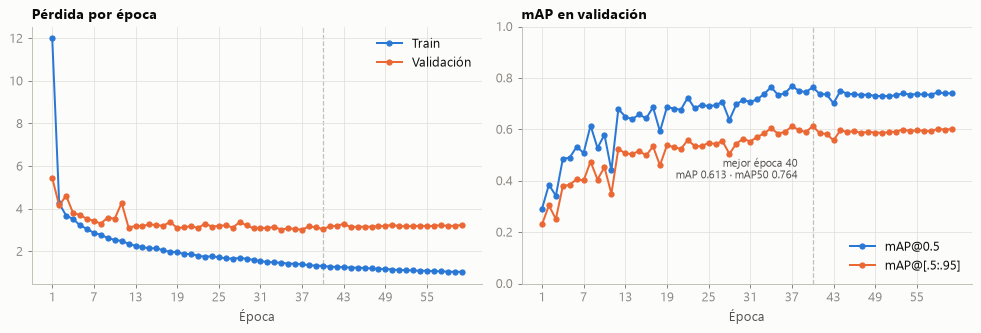

In [4]:
an.plot_training(history, figures_dir / "training_curves.png");

## 3. Curvas PR por especie en test

Una curva por especie a IoU 0.5 y 0.75 (los 101 puntos de recall de COCO). Cuando las dos curvas casi coinciden, las cajas están bien ajustadas: lo que falta es detectar o clasificar mejor.

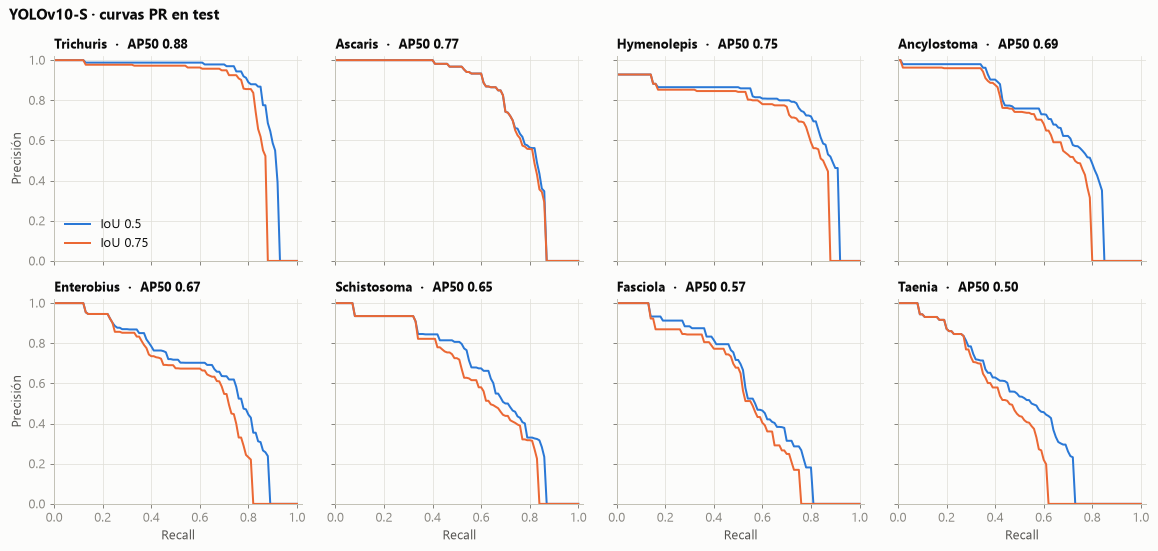

In [5]:
an.plot_pr_curves(pd.read_csv(metrics_dir / "test_pr_curves.csv"), per_class["test"],
                  title="YOLOv10-S · curvas PR en test", path=figures_dir / "pr_curves_test.png");

## 4. AP por especie: validación frente a test

,category_id,name,objects_val,ap_val,ap50_val,objects_test,ap_test,ap50_test
0,1,Ancylostoma Spp,43,0.682,0.781,140,0.527,0.685
1,2,Ascaris Lumbricoides,49,0.651,0.767,115,0.667,0.771
2,3,Enterobius Vermicularis,106,0.583,0.789,154,0.486,0.666
3,4,Fasciola Hepatica,40,0.548,0.668,76,0.465,0.571
4,5,Hymenolepis,43,0.718,0.831,89,0.611,0.747
5,6,Schistosoma,66,0.516,0.663,90,0.498,0.649
6,7,Taenia Sp,53,0.550,0.766,168,0.364,0.495
7,8,Trichuris Trichiura,60,0.647,0.842,131,0.679,0.876


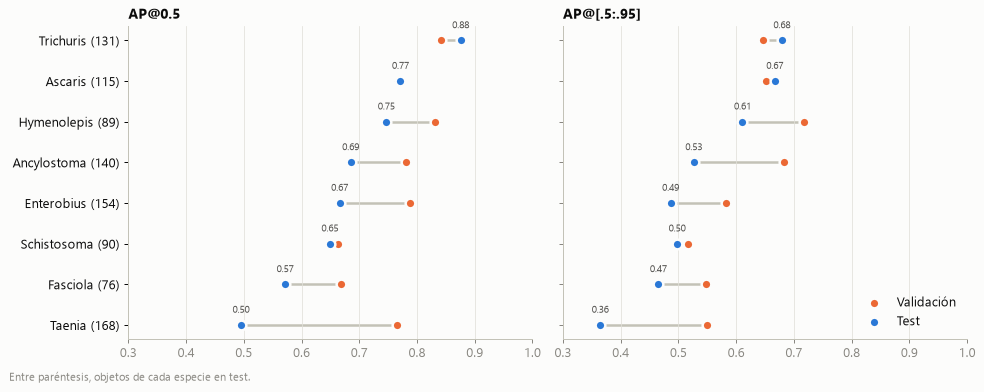

In [6]:
an.plot_ap_val_test(per_class["val"], per_class["test"], path=figures_dir / "ap_per_class_val_test.png")
per_class["val"].merge(per_class["test"], on=["category_id", "name"], suffixes=("_val", "_test")).round(3)

## 5. Umbral de confianza

El mAP no necesita umbral, pero la matriz de confusión y los ejemplos sí. Elegimos el umbral con mayor F1 en **validación** (emparejamiento por clase con IoU ≥ 0.5) y lo aplicamos tal cual a test.

Umbral elegido en validación: 0.30


,threshold,tp,fp,fn,precision,recall,f1
0,0.05,355,210,105,0.628,0.772,0.693
1,0.10,344,151,116,0.695,0.748,0.720
2,0.15,338,124,122,0.732,0.735,0.733
3,0.20,335,101,125,0.768,0.728,0.748
4,0.25,328,87,132,0.790,0.713,0.750
5,0.30,322,73,138,0.815,0.700,0.753
6,0.35,317,67,143,0.826,0.689,0.751
7,0.40,309,65,151,0.826,0.672,0.741
8,0.45,304,56,156,0.844,0.661,0.741
9,0.50,299,51,161,0.854,0.650,0.738


Mismo umbral en test:


,threshold,tp,fp,fn,precision,recall,f1
0,0.3,595,243,368,0.71,0.618,0.661


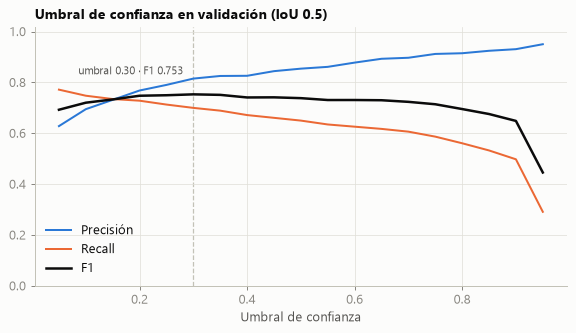

In [7]:
sweep = an.threshold_sweep(coco["val"], predictions["val"])
threshold = float(sweep.loc[sweep["f1"].idxmax(), "threshold"])
an.plot_threshold_sweep(sweep, threshold, path=figures_dir / "threshold_val.png")
print(f"Umbral elegido en validación: {threshold:.2f}")
display(sweep.round(3))
print("Mismo umbral en test:")
an.threshold_sweep(coco["test"], predictions["test"], thresholds=[threshold]).round(3)

## 6. Matriz de confusión en test

Cada detección con confianza ≥ umbral se empareja, de mayor a menor confianza, con la caja real libre de mayor IoU (≥ 0.5) de **cualquier** clase. Así se ve con qué especie se confunde cada una. La fila *Fondo* son detecciones donde no hay ningún huevo; la columna *No detectado*, huevos sin ninguna detección. El color está normalizado por fila.

,Ancylostoma,Ascaris,Enterobius,Fasciola,Hymenolepis,Schistosoma,Taenia,Trichuris,No detectado
Ancylostoma,68,2,0,5,1,1,0,1,62
Ascaris,8,77,0,4,2,4,1,0,19
Enterobius,1,0,114,3,0,1,0,0,35
Fasciola,4,3,1,41,0,2,1,0,24
Hymenolepis,0,1,0,0,66,2,3,0,17
Schistosoma,0,0,2,5,1,53,0,0,29
Taenia,0,0,0,1,10,0,73,1,83
Trichuris,3,0,5,1,0,1,0,103,18
Fondo,8,6,64,15,6,14,42,7,0


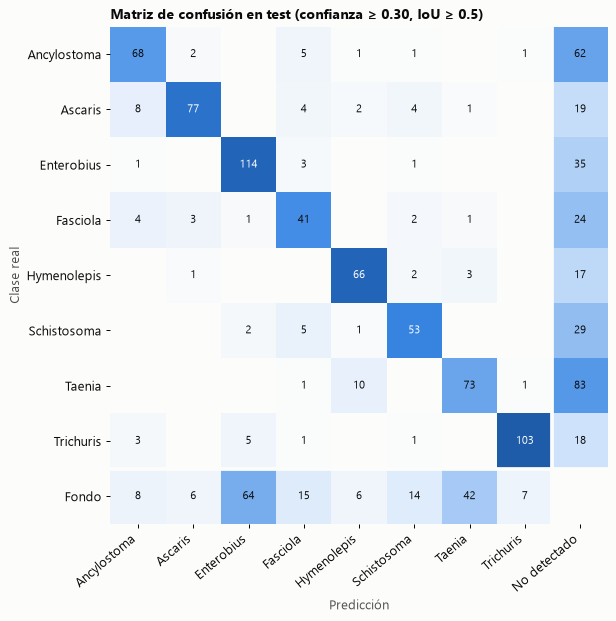

In [8]:
confusion = an.confusion_matrix(coco["test"], predictions["test"], threshold)
an.plot_confusion(confusion, threshold, path=figures_dir / "confusion_matrix_test.png")
confusion

## 7. ¿Dónde se pierde el mAP? Errores tipo TIDE

Desglose simplificado de TIDE de `mapviz` (sección 9 del notebook de la práctica), con todas las detecciones y a IoU 0.5. Cada detección errónea se asigna a un tipo:

| tipo | definición |
|---|---|
| clasificación | IoU ≥ 0.5 con un huevo de otra especie |
| localización | IoU entre 0.1 y 0.5 con algún huevo |
| duplicado | IoU ≥ 0.5 con un huevo que ya tiene una detección de mayor confianza |
| fondo | IoU < 0.1 con todos los huevos |
| no detectado | huevo sin ninguna detección que lo explique |

Un oráculo corrige solo un tipo, se recalcula el mAP@0.5 y se anota la ganancia. Importa la ganancia, no el número de casos: un error de confianza 0.06 casi no resta AP.

mAP@0.5 de mapviz: 0.6825 | pycocotools: 0.6825


,error,key,count,delta_map50
0,Clasificación,cls,1136,0.1191
1,Localización,loc,77,0.0090
2,Duplicado,dup,384,0.0109
3,Fondo,bg,829,0.0505
4,No detectado,miss,72,0.0165


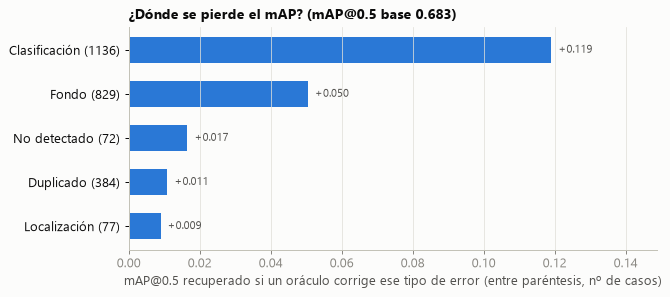

In [9]:
breakdown, errors_table = an.error_breakdown(coco["test"], predictions["test"])
an.plot_error_breakdown(errors_table, breakdown["base"], path=figures_dir / "error_breakdown_test.png")
print(f"mAP@0.5 de mapviz: {breakdown['base']:.4f} | pycocotools: {metrics['test']['map50']:.4f}")
errors_table.round(4)

## 8. Ejemplos cualitativos

Con el umbral de validación. Verde: detección correcta; rojo: detección errónea con su tipo de error; ámbar discontinuo: huevo no detectado.

### 8.1 Una detección correcta por especie

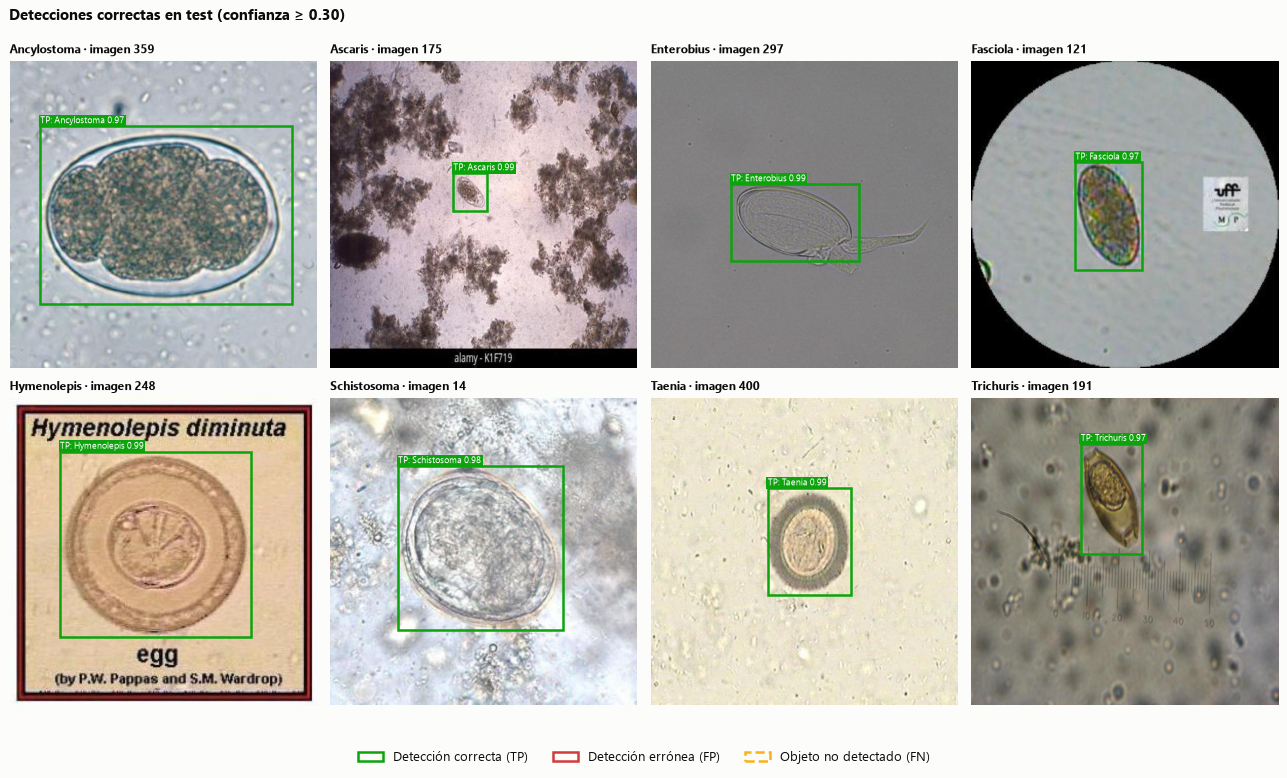

In [10]:
per_image = an.image_errors(coco["test"], predictions["test"], threshold)
correct_ids, correct_names = an.pick_correct_examples(coco["test"], per_image)
an.plot_examples(coco["test"], image_dir, per_image, correct_ids,
                 [f"{n} · imagen {i}" for n, i in zip(correct_names, correct_ids)],
                 suptitle=f"Detecciones correctas en test (confianza ≥ {threshold:.2f})",
                 path=figures_dir / "examples_correct_test.jpg");

### 8.2 Un ejemplo de cada tipo de error

Para cada tipo, el error de mayor confianza, ampliado (para *No detectado*, el huevo más grande sin ninguna detección cerca).

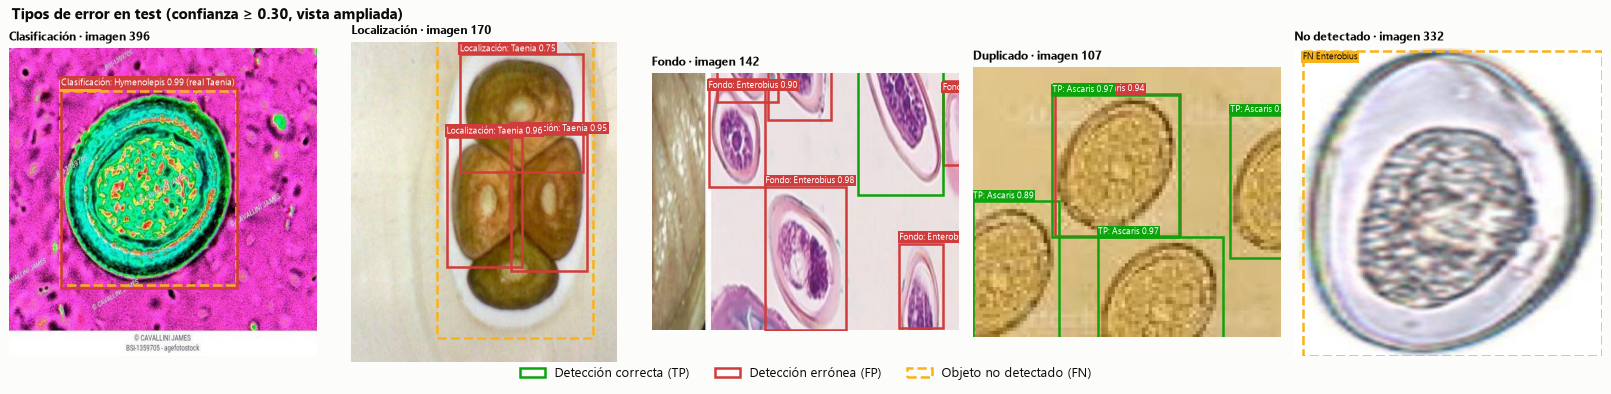

In [11]:
error_ids, error_keys, error_boxes = an.pick_error_examples(per_image)
an.plot_examples(coco["test"], image_dir, per_image, error_ids,
                 [f"{an.ERROR_LABELS[k]} · imagen {i}" for k, i in zip(error_keys, error_ids)],
                 ncols=len(error_ids), focus=error_boxes,
                 suptitle=f"Tipos de error en test (confianza ≥ {threshold:.2f}, vista ampliada)",
                 path=figures_dir / "examples_errors_test.jpg");

### 8.3 Imágenes con más errores

En las imágenes con muchas cajas se omiten los textos y el título da el recuento. La tabla cuenta, por especie, los huevos sin detección correcta (incluye los que tienen una detección de otra clase o mal ajustada) y si se concentran en pocas imágenes.

,especie,no_detectados,imagenes,en_top3,top3_imagenes
6,Taenia,95,25,54,"193 (26), 126 (18), 73 (10)"
0,Ancylostoma,72,25,34,"47 (24), 238 (5), 298 (5)"
2,Enterobius,40,17,21,"90 (10), 203 (6), 77 (5)"
1,Ascaris,38,27,11,"16 (6), 240 (3), 200 (2)"
5,Schistosoma,37,22,15,"86 (7), 144 (5), 67 (3)"
3,Fasciola,35,24,12,"141 (5), 49 (4), 12 (3)"
7,Trichuris,28,23,8,"3 (3), 216 (3), 124 (2)"
4,Hymenolepis,23,19,7,"99 (4), 62 (2), 269 (1)"


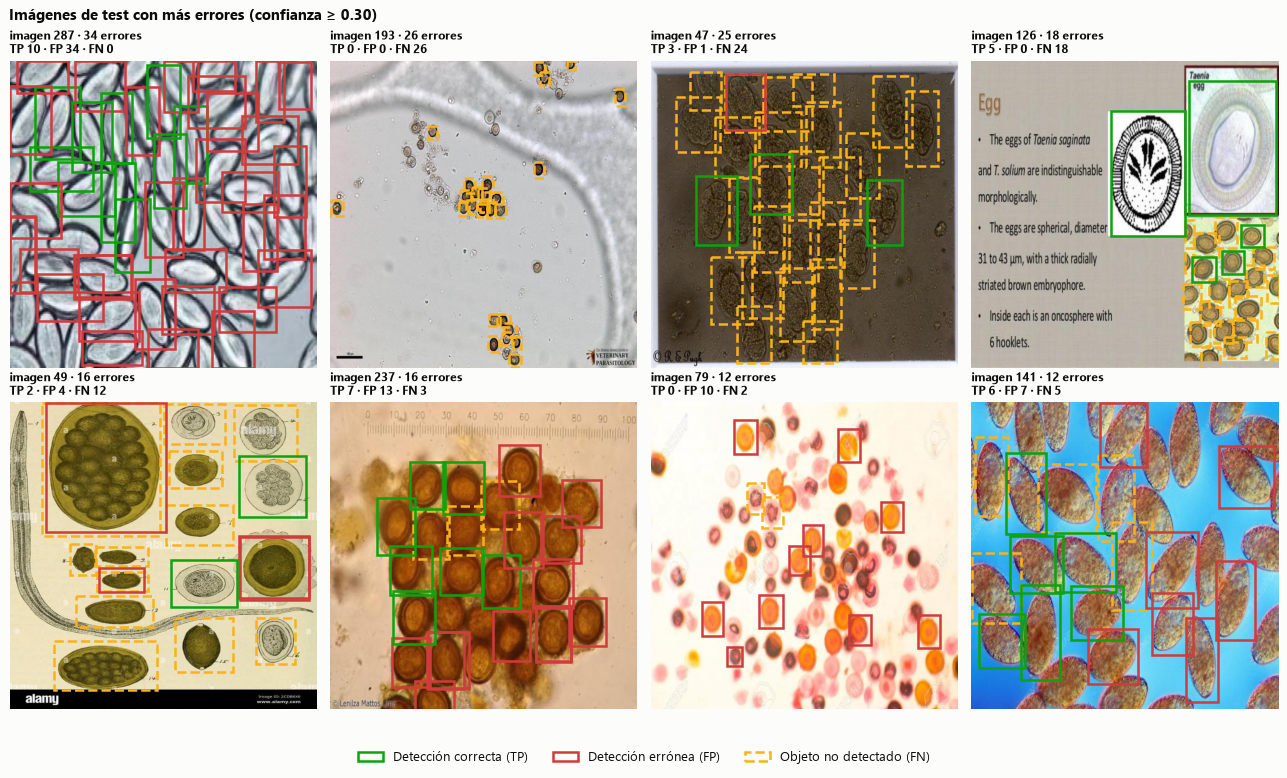

In [12]:
worst_ids, counts = an.worst_images(per_image, n=8)
an.plot_examples(coco["test"], image_dir, per_image, worst_ids,
                 [f"imagen {i} · {counts[i]} errores" for i in worst_ids],
                 suptitle=f"Imágenes de test con más errores (confianza ≥ {threshold:.2f})",
                 path=figures_dir / "examples_worst_test.jpg")
an.missed_by_class(coco["test"], per_image)

## 9. Observaciones (baseline, 28-11-2026)

Lo que muestran las cifras y figuras de arriba; las interpretaciones marcadas como hipótesis están por comprobar.

- **El checkpoint se reproduce**: mAP de validación 0.612 frente a 0.613 al entrenar. La diferencia es numérica (aquí CPU en FP32, en el entrenamiento GPU) y mucho menor que el ruido entre entrenamientos idénticos (unas 0.006 en Faster R-CNN).
- **Test cae bastante más que validación**: mAP@[.5:.95] 0.537 frente a 0.612 (−0.075) y mAP@0.5 0.683 frente a 0.763. En Faster R-CNN la caída es de −0.040. En test, **Faster R-CNN supera a YOLOv10-S en las ocho especies** (mAP 0.623 frente a 0.537).
- **La localización tampoco es el problema**: mAP@0.75 (0.638) está cerca de mAP@0.5 (0.683) y corregirla solo daría +0.009.
- **Lo que más cuesta vuelve a ser la clasificación** (+0.119 de mAP@0.5) y después las **detecciones de fondo** (+0.051). A diferencia de Faster R-CNN, aparecen **duplicados** (384, +0.011): la cabeza one-to-one de YOLOv10 no usa NMS y a veces deja dos cajas sobre el mismo huevo.
- **Taenia es la peor especie** (AP@0.5 0.495). De sus 95 huevos sin detección correcta, 54 están en tres imágenes: 193 (26), 126 (18) y 73 (10). Las dos primeras son las mismas que hunden a Taenia en Faster R-CNN (huevos muy pequeños y agrupados; collage de diapositiva). El AP de objetos pequeños cae a 0.03 (Faster R-CNN 0.25), aunque en test solo hay 36 objetos pequeños.
- **Ancylostoma** pierde 62 huevos y 24 están en una sola imagen (47).
- Con el umbral de validación, los falsos positivos de fondo se concentran en *Enterobius* (64) y *Taenia* (42).
- **Umbral**: en validación, el F1 máximo está en 0.30 (0.753) y es casi plano entre 0.20 y 0.45. YOLO da confianzas más bajas que Faster R-CNN (cuyo óptimo estaba en 0.90). En test, con 0.30, F1 0.661.
- **Inferencia**: mediana de 265 ms por imagen en CPU (Intel, 10 hilos, lote 1), unas **12.6 veces más rápido que Faster R-CNN** en la misma imagen y en el mismo momento.
- *Hipótesis*: la mayor caída de val a test indica que YOLO generaliza peor con este train pequeño y sin aumentos de datos (60 épocas, mejor en la 40). Los aumentos de datos deberían ayudarle más que a Faster R-CNN.

Líneas de mejora que salen de aquí: aumentos de datos; más resolución para los huevos pequeños; y, como en Faster R-CNN, analizar el error por tipo de imagen.